In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity
import ast


In [76]:
import matplotlib.pyplot as plt

# Carregando os dados

In [2]:
ads_base = pd.read_csv('../data/ads.csv')
users_base = pd.read_csv('../data/users.csv')

users= users_base.copy()
ads = ads_base.copy()

In [3]:
users.head(1)

,user_id,age,gender,state,city,preferences
0,0,58,F,MG,Juiz de Fora,"[('Sports_Games', 0.06144033651140886), ('Cons..."


In [4]:
ads.head(1)

,ad_id,state_target,city_target,age_target,gender_target,categories,bid,budget,trust_score,estimated_conversion_rate
0,0,PR,Maringá,60,F,"{'Indie_Games': 0.16518794390557134, 'Open_Wor...",15.0,7500.0,0.940094,0.016979


# Simples transformação de dados

In [5]:
type(ads.categories)

pandas.core.series.Series

In [6]:
type(users.preferences)

pandas.core.series.Series

In [7]:
# CSV perde a informação de tipo, então precisamos converter as strings de volta para listas e para dicionários. Para isso, podemos usar a função ast.literal_eval, que avalia uma string como uma expressão Python e retorna o objeto correspondente.

users["preferences"] = users["preferences"].apply(ast.literal_eval)
ads['categories'] = ads['categories'].apply(ast.literal_eval)

# Features Categorias

Gerar as categorias com seus pesos

OBS: isso foi feito porque para trabalhar com a abordagem de vetores, ADS e Users devem possuir mesma dimensões

Depois desenvolver uma forma mais inteligente para não fazer à mão

Ideia para desenvolver:

- código que ao ler os dados de preferences e categories, salva em uma lista os valores únicos

In [8]:
# fazendo à mão

all_categories  = [
"FPS",
"Battle_Royale",
"MOBA",
"RPG",
"MMORPG",
"Strategy",
"Simulation",
"Sports_Games",
"Racing",
"Indie_Games",
"Retro_Gaming",
"Mobile_Gaming",
"PC_Gaming",
"Console_Gaming",
"Game_Development",
"Game_Streaming",
"Esports",
"Game_Hardware",
"VR_Gaming",
"Open_World",
"League_of_Legends",
"Fortnite",
"Minecraft",
"Counter_Strike",
"World_of_Warcraft"
]

In [9]:
# enumerar as categorias para criar um índice de categoria, que será usado para construir os vetores de características dos usuários e dos anúncios.
category_index = {cat: i for i, cat in enumerate(all_categories)}


In [10]:
# função para construir o vetor de características do usuário a partir de suas preferências, usando o índice de categoria para mapear as categorias para posições no vetor.

def build_user_vector(preferences, category_index):

    vector = np.zeros(len(category_index))

    for category, weight in preferences:
        if category in category_index:
            vector[category_index[category]] = weight

    return vector

In [11]:
# fazendo um teste para ver se a função build_user_vector está funcionando corretamente, construindo o vetor de características do primeiro usuário do dataset.
teste = build_user_vector(users.iloc[0]['preferences'], category_index)
display(teste)
display(users.iloc[0]['preferences'])
display(category_index)

array([0.        , 0.        , 0.        , 0.        , 0.17928986,
       0.        , 0.        , 0.06144034, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.16123711, 0.        ,
       0.        , 0.04964747, 0.0894841 , 0.01684707, 0.        ,
       0.        , 0.32530896, 0.03901933, 0.07772577, 0.        ])

[('Sports_Games', 0.06144033651140886),
 ('Console_Gaming', 0.16123710711415512),
 ('MMORPG', 0.17928985804561),
 ('VR_Gaming', 0.016847073302291835),
 ('Minecraft', 0.03901932791588827),
 ('Fortnite', 0.3253089551775492),
 ('Esports', 0.04964746680902405),
 ('Counter_Strike', 0.07772577069622656),
 ('Game_Hardware', 0.0894841044278461)]

{'FPS': 0,
 'Battle_Royale': 1,
 'MOBA': 2,
 'RPG': 3,
 'MMORPG': 4,
 'Strategy': 5,
 'Simulation': 6,
 'Sports_Games': 7,
 'Racing': 8,
 'Indie_Games': 9,
 'Retro_Gaming': 10,
 'Mobile_Gaming': 11,
 'PC_Gaming': 12,
 'Console_Gaming': 13,
 'Game_Development': 14,
 'Game_Streaming': 15,
 'Esports': 16,
 'Game_Hardware': 17,
 'VR_Gaming': 18,
 'Open_World': 19,
 'League_of_Legends': 20,
 'Fortnite': 21,
 'Minecraft': 22,
 'Counter_Strike': 23,
 'World_of_Warcraft': 24}

In [12]:
# função análoga para o ads
# feito isso pq o ads foi salvo como dict e user como list

def build_ad_vector(categories, category_index):

    vector = np.zeros(len(category_index))

    for category, weight in categories.items():
        if category in category_index:
            vector[category_index[category]] = weight

    return vector

In [13]:
# teste para ads
teste_ad = build_ad_vector(ads.iloc[0]['categories'], category_index)
display(teste_ad)
display(ads.iloc[0]['categories'])


array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.09308321, 0.        , 0.        , 0.16518794,
       0.31308539, 0.        , 0.01383063, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.22099246, 0.06033233,
       0.13348803, 0.        , 0.        , 0.        , 0.        ])

{'Indie_Games': 0.16518794390557134,
 'Open_World': 0.060332325664619484,
 'PC_Gaming': 0.013830634132233021,
 'Simulation': 0.09308320786155601,
 'League_of_Legends': 0.13348803361729053,
 'VR_Gaming': 0.22099246159470362,
 'Retro_Gaming': 0.3130853932240261}

In [14]:
# aplcar as funções para construir os vetores de características para todos os usuários e anúncios, e armazenar esses vetores em novas colunas nos dataframes.

users['feature_vector'] = users['preferences'].apply(lambda prefs: build_user_vector(prefs, category_index))
ads['feature_vector'] = ads['categories'].apply(lambda cats: build_ad_vector(cats, category_index))

In [15]:
users.head(1)

,user_id,age,gender,state,city,preferences,feature_vector
0,0,58,F,MG,Juiz de Fora,"[(Sports_Games, 0.06144033651140886), (Console...","[0.0, 0.0, 0.0, 0.0, 0.17928985804561, 0.0, 0...."


# Features demográficas

Uma estratégia é adicionar essas features ao vetor, só que aumenta bastante a dimensionalidade.

Inicialmente, vamos fazer one-hot encoding, mas é melhor pensar em outras estratégias
-   nessas situações, há 25 cidades distintas

In [16]:
ALL_CITIES = sorted(
    set(users["city"].unique()) |
    set(ads["city_target"].unique())
)

In [17]:
ALL_STATES = sorted(
    set(users["state"].unique()) | 
    set(ads["state_target"].unique())
)

In [18]:
def one_hot_city(city, all_cities):

    vector = {f"city_{c}": 0 for c in all_cities}

    if city in all_cities:
        vector[f"city_{city}"] = 1

    return vector

In [19]:
def one_hot_state(state, all_states):

    vector = {f"state_{s}": 0 for s in all_states}

    if state in all_states:
        vector[f"state_{state}"] = 1

    return vector

In [20]:
city_features = users["city"].apply(
    lambda x: pd.Series(one_hot_city(x, ALL_CITIES))
)

city_features_ads = ads["city_target"].apply(
    lambda x: pd.Series(one_hot_city(x, ALL_CITIES))
)

In [21]:
state_features = users["state"].apply(
    lambda x: pd.Series(one_hot_state(x, ALL_STATES))
)
state_features_ads = ads["state_target"].apply(
    lambda x: pd.Series(one_hot_state(x, ALL_STATES))
)

In [22]:
users = pd.concat([users, city_features], axis=1)
ads = pd.concat([ads, city_features_ads], axis=1)

In [23]:
users = pd.concat([users, state_features], axis=1)
ads = pd.concat([ads, state_features_ads], axis=1)

### Feature genero

In [24]:
# One-hot encoding para Genero
gender_dummies = pd.get_dummies(users["gender"], prefix="gender")
users = pd.concat([users, gender_dummies], axis=1)

gender_dummies_ads = pd.get_dummies(ads["gender_target"], prefix="gender")
ads = pd.concat([ads, gender_dummies_ads], axis=1)

### Feature Idade

In [25]:
# a idade targe só tem uma idade fixa, então faz sentido normalizar.
# isso vai acontecer ou o anúncio vai ter uma faixa de valores??

In [26]:
users['age_norm'] = (users['age'] - users['age'].min()) / (users['age'].max() - users['age'].min())
ads['age_norm'] = (ads['age_target'] - users['age'].min()) / (users['age'].max() - users['age'].min())  

# Gerar os vetores finais

- vai fazer a similaridade tudo junto ou vai separar??

In [27]:
# definir ordem fixa das features

CATEGORY_COLUMNS = all_categories

CITY_COLUMNS = [f"city_{c}" for c in ALL_CITIES]

STATE_COLUMNS = [f"state_{s}" for s in ALL_STATES]

GENDER_COLUMNS = ["gender_F", "gender_M"]

AGE_COLUMNS = ["age_norm"]

In [28]:
users.head(1)

,user_id,age,gender,state,city,preferences,feature_vector,city_Belo Horizonte,city_Betim,city_Camaçari,...,city_Uberlândia,city_Vitória da Conquista,state_BA,state_MG,state_PR,state_RJ,state_SP,gender_F,gender_M,age_norm
0,0,58,F,MG,Juiz de Fora,"[(Sports_Games, 0.06144033651140886), (Console...","[0.0, 0.0, 0.0, 0.0, 0.17928985804561, 0.0, 0....",0,0,0,...,0,0,0,1,0,0,0,True,False,0.952381


In [29]:
# transformar features_vector em colunas separadas
category_features_users = pd.DataFrame(
    users["feature_vector"].tolist(),
    columns=CATEGORY_COLUMNS
)

category_features_ads = pd.DataFrame(
    ads["feature_vector"].tolist(),
    columns=CATEGORY_COLUMNS
)

users = pd.concat([users, category_features_users], axis=1)
ads = pd.concat([ads, category_features_ads], axis=1)

In [30]:
users.iloc[0].preferences

[('Sports_Games', 0.06144033651140886),
 ('Console_Gaming', 0.16123710711415512),
 ('MMORPG', 0.17928985804561),
 ('VR_Gaming', 0.016847073302291835),
 ('Minecraft', 0.03901932791588827),
 ('Fortnite', 0.3253089551775492),
 ('Esports', 0.04964746680902405),
 ('Counter_Strike', 0.07772577069622656),
 ('Game_Hardware', 0.0894841044278461)]

In [31]:
users[category_features_users.columns].iloc[0]

FPS                  0.000000
Battle_Royale        0.000000
MOBA                 0.000000
RPG                  0.000000
MMORPG               0.179290
Strategy             0.000000
Simulation           0.000000
Sports_Games         0.061440
Racing               0.000000
Indie_Games          0.000000
Retro_Gaming         0.000000
Mobile_Gaming        0.000000
PC_Gaming            0.000000
Console_Gaming       0.161237
Game_Development     0.000000
Game_Streaming       0.000000
Esports              0.049647
Game_Hardware        0.089484
VR_Gaming            0.016847
Open_World           0.000000
League_of_Legends    0.000000
Fortnite             0.325309
Minecraft            0.039019
Counter_Strike       0.077726
World_of_Warcraft    0.000000
Name: 0, dtype: float64

In [32]:
# garantir que todas as colunas de cidade, estado e gênero estejam presentes em ambos os dataframes, preenchendo com zeros onde necessário
for col in GENDER_COLUMNS:
    if col not in users:
        users[col] = 0
    if col not in ads:
        ads[col] = 0

In [33]:
for col in CITY_COLUMNS:
    if col not in users:
        users[col] = 0
    if col not in ads:
        ads[col] = 0

for col in STATE_COLUMNS:
    if col not in users:
        users[col] = 0
    if col not in ads:
        ads[col] = 0

In [34]:
FINAL_FEATURE_COLUMNS = (
    CATEGORY_COLUMNS +
    CITY_COLUMNS +
    STATE_COLUMNS +
    GENDER_COLUMNS +
    AGE_COLUMNS
)

In [35]:
users.head(1)

,user_id,age,gender,state,city,preferences,feature_vector,city_Belo Horizonte,city_Betim,city_Camaçari,...,Game_Streaming,Esports,Game_Hardware,VR_Gaming,Open_World,League_of_Legends,Fortnite,Minecraft,Counter_Strike,World_of_Warcraft
0,0,58,F,MG,Juiz de Fora,"[(Sports_Games, 0.06144033651140886), (Console...","[0.0, 0.0, 0.0, 0.0, 0.17928985804561, 0.0, 0....",0,0,0,...,0.0,0.049647,0.089484,0.016847,0.0,0.0,0.325309,0.039019,0.077726,0.0


In [36]:
users[FINAL_FEATURE_COLUMNS]

,FPS,Battle_Royale,MOBA,RPG,MMORPG,Strategy,Simulation,Sports_Games,Racing,Indie_Games,...,city_Uberlândia,city_Vitória da Conquista,state_BA,state_MG,state_PR,state_RJ,state_SP,gender_F,gender_M,age_norm
0,0.000000,0.0,0.000000,0.0,0.179290,0.000000,0.000000,0.061440,0.00000,0.0,...,0,0,0,1,0,0,0,True,False,0.952381
1,0.000000,0.0,0.536367,0.0,0.000000,0.000000,0.000000,0.463633,0.00000,0.0,...,0,0,0,0,0,1,0,True,False,0.547619
2,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.113223,0.000000,0.00000,0.0,...,0,0,0,0,0,0,1,True,False,0.738095
3,0.000000,0.0,0.000000,0.0,0.257160,0.000000,0.405503,0.000000,0.00000,0.0,...,0,0,0,0,0,0,1,False,True,0.857143
4,0.637649,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.0,...,0,0,0,0,0,1,0,True,False,0.714286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0.000000,0.0,0.000000,0.0,0.722629,0.049078,0.000000,0.000000,0.10887,0.0,...,0,0,0,0,0,0,1,False,True,0.619048
9996,0.155263,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.0,...,0,0,1,0,0,0,0,False,True,0.380952
9997,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.00000,0.0,...,0,0,0,0,0,0,1,True,False,0.190476
9998,0.000000,0.0,0.000000,0.0,0.000000,0.607445,0.000000,0.000000,0.00000,0.0,...,0,0,0,0,0,0,1,False,True,0.000000


In [37]:
ads[FINAL_FEATURE_COLUMNS]

,FPS,Battle_Royale,MOBA,RPG,MMORPG,Strategy,Simulation,Sports_Games,Racing,Indie_Games,...,city_Uberlândia,city_Vitória da Conquista,state_BA,state_MG,state_PR,state_RJ,state_SP,gender_F,gender_M,age_norm
0,0.0,0.00000,0.000000,0.000000,0.000000,0.0,0.093083,0.000000,0.0,0.165188,...,0,0,0,0,1,0,0,True,False,1.000000
1,0.0,0.00000,0.000000,0.000000,0.604446,0.0,0.000000,0.000000,0.0,0.000000,...,0,0,1,0,0,0,0,False,True,0.976190
2,0.0,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0,0,0,1,0,0,0,True,False,0.833333
3,0.0,0.00000,0.000000,0.000000,0.917360,0.0,0.000000,0.000000,0.0,0.000000,...,0,0,0,1,0,0,0,True,False,0.285714
4,0.0,0.00000,0.000000,0.375844,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0,0,1,0,0,0,0,True,False,0.809524
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,0.0,0.03772,0.000000,0.895510,0.066771,0.0,0.000000,0.000000,0.0,0.000000,...,0,0,0,0,0,1,0,True,False,0.071429
496,0.0,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.062387,0.0,0.000000,...,0,0,1,0,0,0,0,False,True,0.452381
497,0.0,0.00000,0.000000,0.000000,0.000000,0.0,0.000000,0.185780,0.0,0.000000,...,0,0,0,0,0,1,0,False,True,0.285714
498,0.0,0.00000,0.046294,0.000000,0.000000,0.0,0.953706,0.000000,0.0,0.000000,...,0,0,0,0,0,1,0,False,True,0.690476


In [38]:
user_matrix = users[FINAL_FEATURE_COLUMNS].values
ad_matrix = ads[FINAL_FEATURE_COLUMNS].values

# PRECISA NORMALIZAR???

In [39]:
user_matrix

array([[0.0, 0.0, 0.0, ..., True, False, 0.9523809523809523],
       [0.0, 0.0, 0.5363673412882524, ..., True, False,
        0.5476190476190477],
       [0.0, 0.0, 0.0, ..., True, False, 0.7380952380952381],
       ...,
       [0.0, 0.0, 0.0, ..., True, False, 0.19047619047619047],
       [0.0, 0.0, 0.0, ..., False, True, 0.0],
       [0.0, 0.0, 0.0, ..., False, True, 0.6428571428571429]],
      shape=(10000, 58), dtype=object)

**cosine similarity**

Mede a similaridade de direção entre dois vetores, calculando o cosseno do ângulo entre eles, usando o produto escalar normalizado pela magnitude dos vetores.

In [40]:
similarity_matrix = cosine_similarity(user_matrix, ad_matrix)

In [41]:
similarity_matrix
# cada linha representa um usuário e cada coluna representa um anúncio, e os valores são as similaridades entre eles.

array([[0.47153176, 0.24981313, 0.63731514, ..., 0.08236718, 0.15515928,
        0.15824168],
       [0.38705477, 0.12998388, 0.3446966 , ..., 0.32779277, 0.34343886,
        0.33327958],
       [0.45926929, 0.16862957, 0.40580891, ..., 0.05354563, 0.14552527,
        0.0784481 ],
       ...,
       [0.30637519, 0.04652391, 0.36367994, ..., 0.01477293, 0.03313002,
        0.02164337],
       [0.        , 0.25365693, 0.        , ..., 0.35389934, 0.25537482,
        0.28459703],
       [0.15691192, 0.92024834, 0.12374789, ..., 0.31915951, 0.34496195,
        0.33553204]], shape=(10000, 500))

In [ ]:
# adicionar um erro??
score = similarity_matrix + np.random.normal(0, 0.01, similarity_matrix.shape)

**Sugestão de outra técnica**:

ANN candidate generation. 

# Gerar saídas esperadas

- Gerar um ranking de ads por relevância pra cada usuário
- Rodar a simulação e ver: quais ads foram entregues, pra quem, com que distribuição

### Gerar um ranking de ads por relevância para cada user

**otimizar essa lógica com numpy**

In [60]:
def gerar_ranking(users_base, ads_base, similarity_matrix, top_k, threshold):

    index_user = users_base.user_id.unique()
    index_ad = ads_base.ad_id.unique()

    # ordenar similaridades (decrescente)
    top_indices = np.argsort(-similarity_matrix, axis=1)[:, :top_k]

    # pegar os valores das similaridades
    top_similarities = np.take_along_axis(similarity_matrix, top_indices, axis=1)

    # gerar ranking
    ranks = np.tile(np.arange(1, top_k + 1), similarity_matrix.shape[0])

    # repetir usuários
    user_ids = np.repeat(index_user, top_k)

    # mapear ids dos ads
    ad_ids = index_ad[top_indices.flatten()]

    # flatten nas similaridades
    similarities = top_similarities.flatten()

    # elegibilidade
    eligible = similarities >= threshold

    df_recommendations = pd.DataFrame({
        "user_id": user_ids,
        "ad_id": ad_ids,
        "similarity": similarities,
        "rank": ranks,
        "eligible": eligible
    })
    return df_recommendations

In [61]:
df_recommendations = gerar_ranking(users, ads, similarity_matrix, top_k=5, threshold=0.5)

### 

Problema com o top ranking deterministico: 

- ADS genéricos tomam conta 

## Quais ads foram entregues e quais são as distribuições?

In [70]:
df_recommendations.head(1)

,user_id,ad_id,similarity,rank,eligible
0,0,152,0.943796,1,True


In [73]:
ads_delivered = df_recommendations.query('eligible == True').groupby(["ad_id"]).agg(quantities_delivered=('ad_id', 'count') ,
                                                                    users = ('user_id', list),
                                                                    similarity_min = ('similarity', 'min'),
                                                                    similarity_max = ('similarity', 'max'), 
                                                                    similarity_median = ('similarity', 'median'),
                                                                    similarity_mean=('similarity', 'mean') ).reset_index()

In [99]:
ads_delivered.sort_values(by='quantities_delivered')
# ideia avaliar os casos em que o anúncio foi entregue para muitos usuários (olhe para os ads 241 e 414), e os casos em que foi entregue para poucos usuários, para entender se o modelo está entregando anúncios de forma equilibrada ou se está concentrando em poucos anúncios.

,ad_id,quantities_delivered,users,similarity_min,similarity_max,similarity_median,similarity_mean
212,212,2,"[1417, 7929]",0.920131,0.925818,0.922975,0.922975
203,203,2,"[5463, 5602]",0.951533,0.985647,0.968590,0.968590
242,242,4,"[3235, 4707, 8085, 8473]",0.879317,0.990010,0.973740,0.954201
216,216,4,"[4169, 4296, 6415, 8969]",0.851208,0.969140,0.940500,0.925337
322,322,5,"[1190, 1681, 4554, 6508, 7464]",0.925291,0.952170,0.938422,0.937717
...,...,...,...,...,...,...,...
400,400,225,"[36, 142, 146, 194, 199, 305, 317, 347, 367, 3...",0.649975,0.975558,0.906719,0.886162
241,241,226,"[1, 57, 122, 133, 137, 161, 176, 216, 297, 304...",0.642197,0.970389,0.896101,0.892196
414,414,226,"[1, 57, 122, 133, 137, 161, 176, 216, 297, 304...",0.672668,0.968070,0.912232,0.909326
376,376,229,"[75, 149, 187, 250, 251, 254, 310, 320, 351, 3...",0.679424,0.976694,0.895436,0.879746


## Gerar uma distribuição para um ad

In [97]:
def plot_distribution(df_recommendations, ad_id):
    hist_similarity_ads = df_recommendations.query('ad_id == @ad_id').similarity

    plt.figure(figsize=(10, 6))
    plt.hist(hist_similarity_ads, bins=50)
    plt.title("Histograma - Similarity - Ads ID: {}".format(ad_id))
    plt.xlabel("Similarity")
    plt.ylabel("Frequência")
    #plt.grid(axis='y', alpha=0.75)
    #plt.grid(axis='x', alpha=0.75)

    plt.show()

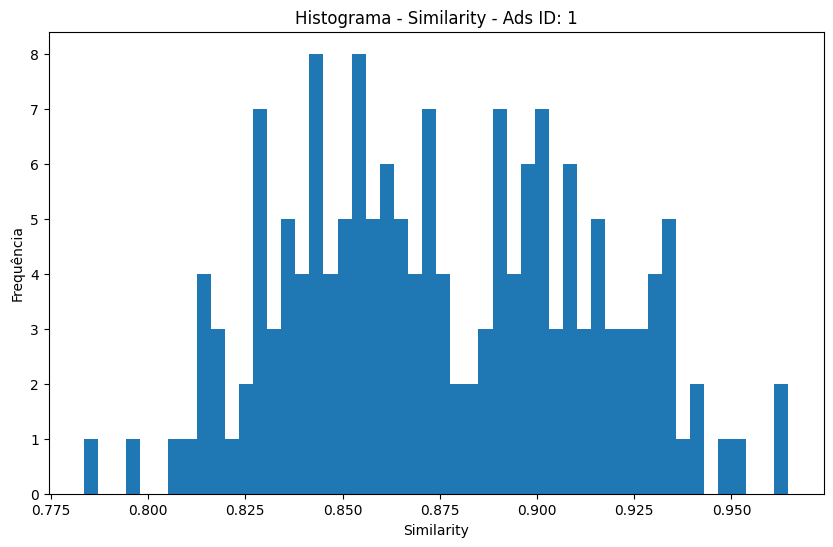

In [98]:
plot_distribution(df_recommendations, ad_id=1)

# Validar os resultados

In [61]:
user_index = 0

scores = similarity_matrix[user_index]

top_ads = similarity_matrix[user_index].argsort()[::-1][:10]

In [56]:
top_ads

array([152, 115, 151, 338, 367, 147, 110, 330,  21, 247])

In [62]:
scores[top_ads]

array([0.94379563, 0.92677986, 0.90478853, 0.87564401, 0.87396446,
       0.86797834, 0.85945246, 0.85677553, 0.84489894, 0.82566807])

In [59]:
ads_base.iloc[top_ads]

,ad_id,state_target,city_target,age_target,gender_target,categories,bid,budget,trust_score,estimated_conversion_rate
152,152,MG,Juiz de Fora,60,F,"{'Counter_Strike': 0.614514113992789, 'Console...",57.504583,57504.582561,0.806772,0.028923
115,115,MG,Juiz de Fora,59,F,"{'VR_Gaming': 0.5233437094183313, 'Minecraft':...",21.308174,2130.817443,0.961975,0.012214
151,151,MG,Juiz de Fora,42,F,"{'Game_Development': 0.5796890742480767, 'Worl...",33.714760,16857.380127,0.991906,0.038818
338,338,MG,Juiz de Fora,27,F,"{'PC_Gaming': 0.14144155141549086, 'Sports_Gam...",20.981378,20981.377913,0.886847,0.035298
367,367,MG,Juiz de Fora,21,F,"{'PC_Gaming': 0.11208083563539241, 'Fortnite':...",16.812757,16812.757363,0.644290,0.010038
147,147,MG,Juiz de Fora,42,F,"{'PC_Gaming': 0.14857127535626957, 'Battle_Roy...",15.000000,1500.000000,0.578580,0.009379
110,110,MG,Juiz de Fora,43,F,{'Sports_Games': 1.0},15.000000,7500.000000,0.726242,0.035685
330,330,MG,Juiz de Fora,23,F,"{'Sports_Games': 0.4177617503847425, 'Racing':...",19.775528,9887.763938,0.870138,0.030988
21,21,MG,Juiz de Fora,43,F,{'Game_Streaming': 1.0},31.879192,31879.192117,0.942092,0.027232
247,247,MG,Juiz de Fora,18,F,"{'Retro_Gaming': 0.4630104530021115, 'Indie_Ga...",21.618254,21618.254103,0.850561,0.011832


In [117]:
users_base.iloc[0]

user_id                                                        0
age                                                           58
gender                                                         F
state                                                         MG
city                                                Juiz de Fora
preferences    [('Sports_Games', 0.06144033651140886), ('Cons...
Name: 0, dtype: object

# **OBJETIVO : score final**

score =
interest_similarity
× demographic_score
× bid
× trust_score
× estimated_conversion_rate

NÃO ESQUECER: incluir as